**ML Lab 1**
<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/marcinsawinski/UEP_KIE_ML_CLASS/blob/main/01_lifesat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

### Note! Check hints in [Cheatsheet](https://colab.research.google.com/github/marcinsawinski/UEP_KIE_ML_LAB_PROG/blob/main/00_cheatsheet.ipynb)

# Task 1-1.1
_Get data and visualize_
- Download lifesat data into pandas dataframe called lifesat available at "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/lifesat.csv"
- Visualize with scatter plot "GDP per capita (USD)" on x axis , "Life satisfaction" of y axis

_Type your code below_

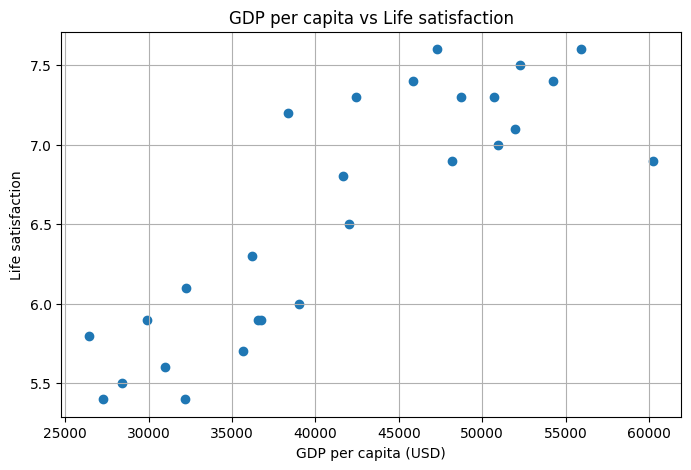

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pobranie danych do ramki lifesat
url = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/lifesat.csv"
lifesat = pd.read_csv(url)

# 2. Wizualizacja za pomocą wykresu punktowego
plt.figure(figsize=(8, 5))
plt.scatter(lifesat["GDP per capita (USD)"], lifesat["Life satisfaction"])

plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("GDP per capita vs Life satisfaction")
plt.grid(True)

plt.show()

# Task 1-1.2
_Train the model and predict_
- Assign new variable X with data from "GDP per capita (USD)" column converted to numpy array
- Assign new variable y with data from "Life satisfaction" column converted to numpy array
- Train linear regression Model for X and y and predict "Life satisfaction" when "GDP per capita (USD)" is equal 37655.2
- Train k-nearest neighbors Model with k=3 for X and y and predict "Life satisfaction" when "GDP per capita (USD)" is equal 37655.2
- Compare linear regression k-nearest neighbors results

_Type your code below_

In [3]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

# 1. Przygotowanie zmiennych X oraz y jako tablice NumPy
# Wymagany jest kształt 2D dla X, stądużycie .values.reshape(-1, 1)
X = lifesat[["GDP per capita (USD)"]].values
y = lifesat["Life satisfaction"].values

# Wartość do predykcji
X_new = np.array([[37655.2]])

# 2. Model Regresji Liniowej
lin_reg = LinearRegression()
lin_reg.fit(X, y)
pred_lin_reg = lin_reg.predict(X_new)[0]

# 3. Model K-Najbliższych Sąsiadów (k=3)
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X, y)
pred_knn = knn.predict(X_new)[0]

# 4. Porównanie wyników
print(f"Predykcja Regresji Liniowej: {pred_lin_reg:.2f}")
print(f"Predykcja K-Najbliższych Sąsiadów (k=3): {pred_knn:.2f}")
print(f"Różnica pomiędzy modelami: {abs(pred_lin_reg - pred_knn):.2f}")

Predykcja Regresji Liniowej: 6.30
Predykcja K-Najbliższych Sąsiadów (k=3): 6.33
Różnica pomiędzy modelami: 0.03


# Task 1-1.3
_Prepare dataset_
- Fetch Better Life Index (BLI) data from [OECD's website](http://stats.oecd.org/index.aspx?DataSetCode=BLI) (to get the Life Satisfaction for each country), and World Bank GDP per capita data from [OurWorldInData.org](https://ourworldindata.org/grapher/gdp-per-capita-worldbank)

files are copied here:

https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/gdp-per-capita-worldbank.csv
https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/oecd_bli_20221109.csv
- Preview fetched data
- Filter one 1 selected year
- Merge the life satisfaction data and the GDP per capita data, keeping only the GDP per capita and Life satisfaction columns
- Visuilza data on scatter plot
- Add linear regresion prediciton for countries with no Life satisfaction to the plot
- Add k-nearest neighbors prediciton for countries with no Life satisfaction to the plot

_Type your code below_

--- GDP Data Preview ---
        Entity Code  Year  GDP per capita, PPP (constant 2017 international $)
0  Afghanistan  AFG  2002                                        1189.784668  
1  Afghanistan  AFG  2003                                        1235.810059  
2  Afghanistan  AFG  2004                                        1200.277954  
3  Afghanistan  AFG  2005                                        1286.793701  
4  Afghanistan  AFG  2006                                        1315.789062  

--- OECD BLI Data Preview ---
  LOCATION         Country INDICATOR                 Indicator MEASURE  \
0      AUS       Australia   JE_LMIS  Labour market insecurity       L   
1      AUT         Austria   JE_LMIS  Labour market insecurity       L   
2      BEL         Belgium   JE_LMIS  Labour market insecurity       L   
3      CAN          Canada   JE_LMIS  Labour market insecurity       L   
4      CZE  Czech Republic   JE_LMIS  Labour market insecurity       L   

  Measure INEQUALITY Ineq

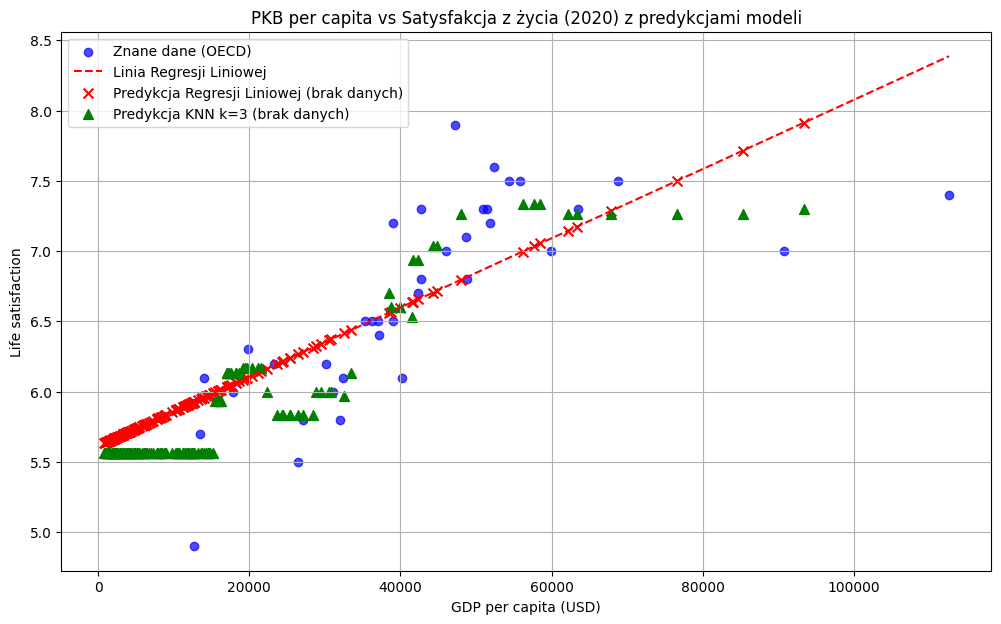

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

# 1. Pobranie danych
gdp_url = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/gdp-per-capita-worldbank.csv"
oecd_url = "https://github.com/marcinsawinski/UEP_KIE_ML_CLASS/raw/main/datasets/lifesat/oecd_bli_20221109.csv"

gdp_df = pd.read_csv(gdp_url)
oecd_df = pd.read_csv(oecd_url)

# 2. Podgląd danych
print("--- GDP Data Preview ---")
print(gdp_df.head())
print("\n--- OECD BLI Data Preview ---")
print(oecd_df.head())

# 3. Filtrowanie danych do 1 wybranego roku (np. 2020)
# Filtrowanie dla GDP
gdp_2020 = gdp_df[gdp_df["Year"] == 2020].copy()

# Filtrowanie dla OECD BLI (wybieramy wskaźnik 'Life satisfaction' oraz ogólną wartość dla 'TOT')
oecd_ls = oecd_df[(oecd_df["INEQUALITY"] == "TOT") & (oecd_df["Indicator"] == "Life satisfaction")].copy()

# Dostosowanie nazw kolumn przed scaleniem
gdp_col_name = [c for c in gdp_2020.columns if "GDP" in c or "gdp" in c or "Entity" in c or "Code" in c]
# Szukamy kolumny z wartością GDP per capita
gdp_val_col = [c for c in gdp_2020.columns if c not in ["Entity", "Code", "Year"]][0]

gdp_2020 = gdp_2020.rename(columns={"Entity": "Country", gdp_val_col: "GDP per capita (USD)"})
oecd_ls = oecd_ls.rename(columns={"Country": "Country", "Value": "Life satisfaction"})

# 4. Scalenie danych (Merge)
# Wykorzystujemy outer merge, aby zachować też kraje mające tylko GDP (brak Life satisfaction)
merged_df = pd.merge(gdp_2020[["Country", "GDP per capita (USD)"]],
                     oecd_ls[["Country", "Life satisfaction"]],
                     on="Country",
                     how="outer")

# Rozdzielenie na zbiór z kompletnymi danymi oraz zbiór z brakiem Life satisfaction (ale obecnym GDP)
known_df = merged_df.dropna(subset=["GDP per capita (USD)", "Life satisfaction"]).copy()
missing_ls_df = merged_df[merged_df["Life satisfaction"].isna() & merged_df["GDP per capita (USD)"].notna()].copy()

# 5. Trenowanie modeli na znanych danych
X_train = known_df[["GDP per capita (USD)"]].values
y_train = known_df["Life satisfaction"].values

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X_train, y_train)

# Predykcje dla krajów z brakiem Life satisfaction
X_missing = missing_ls_df[["GDP per capita (USD)"]].values
missing_ls_df["LS_Pred_LinReg"] = lin_reg.predict(X_missing)
missing_ls_df["LS_Pred_KNN"] = knn.predict(X_missing)

# 6. Wizualizacja danych i predykcji na wykresie
plt.figure(figsize=(12, 7))

# Wykres punktowy dla znanych danych
plt.scatter(known_df["GDP per capita (USD)"], known_df["Life satisfaction"],
            color="blue", alpha=0.7, label="Znane dane (OECD)")

# Linia trendu dla regresji liniowej
X_plot = np.linspace(X_train.min(), X_train.max(), 1000).reshape(-1, 1)
plt.plot(X_plot, lin_reg.predict(X_plot), color="red", linestyle="--", label="Linia Regresji Liniowej")

# Predykcje dla brakujących krajów - Regresja Liniowa
plt.scatter(missing_ls_df["GDP per capita (USD)"], missing_ls_df["LS_Pred_LinReg"],
            color="red", marker="x", s=50, label="Predykcja Regresji Liniowej (brak danych)")

# Predykcje dla brakujących krajów - KNN (k=3)
plt.scatter(missing_ls_df["GDP per capita (USD)"], missing_ls_df["LS_Pred_KNN"],
            color="green", marker="^", s=50, label="Predykcja KNN k=3 (brak danych)")

plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.title("PKB per capita vs Satysfakcja z życia (2020) z predykcjami modeli")
plt.legend()
plt.grid(True)

plt.show()